# Visualize Box Diffusion Results

Load a trained `BoxSetDiffusionDecoder` checkpoint and visualize predicted bounding boxes
alongside ground-truth annotations on CrowdPose images.

In [9]:
%matplotlib inline

In [14]:
from pathlib import Path

# ── Paths ─────────────────────────────────────────────────────────────────────
RUN_DIR = Path("results/box_diffusion_benchmark/box_diffusion_benchmark/20260524_124837")
CKPT_PATH = RUN_DIR / "checkpoints/epoch099-val_bbox_AP.ckpt"
HYDRA_CFG = RUN_DIR / ".hydra/config.yaml"

ANN_DIR  = Path("data/crowdpose/annotations")
IMG_ROOT = Path("data/crowdpose/images")
SPLIT    = "val"  # val | test

# ── Inference settings ────────────────────────────────────────────────────────
MAX_SIZE           = 128   # resize longest side to this before backbone
NUM_INFERENCE_STEPS = 5    # EDM Heun steps (1 = single-step x0 prediction)
SCORE_THRESH       = 0.5   # objectness threshold for predicted boxes
TOP_K              = 20    # max predicted boxes shown per image

# ── Visualisation ─────────────────────────────────────────────────────────────
N_IMAGES = 8   # images to show in the grid
SEED     = 0

DEVICE = "cuda"  # cpu | cuda

In [11]:
import random
import sys
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision.io as tvio
import torchvision.transforms.functional as TF
from omegaconf import OmegaConf
from torchvision.transforms import InterpolationMode

# Ensure the workspace root is on the path
ROOT = Path(".").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.data_module import resize_and_pad_to_square
from src.data.datasets import PoseDataset
from src.data.transforms import boxes_padded_canonical_to_pixel_xywh
from src.decoders.diffusion.box_set import BoxSetDiffusionDecoderConfig
from src.features import BaseFeatureExtractorConfig
from src.training.box_diffusion_module import _image_tokens_and_centers

## 1. Build backbone + decoder and load checkpoint

In [12]:
import json

raw_cfg = OmegaConf.load(HYDRA_CFG)

backbone_cfg = BaseFeatureExtractorConfig.from_hydra_config(raw_cfg.backbone)
decoder_cfg  = BoxSetDiffusionDecoderConfig.from_hydra_config(raw_cfg.decoder)

backbone = backbone_cfg.build()
decoder_cfg.image_token_dim = backbone.out_channels
decoder = decoder_cfg.build()

ckpt = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
sd = ckpt["state_dict"]

backbone.load_state_dict({k[len("backbone."):]: v for k, v in sd.items() if k.startswith("backbone.")})
decoder.load_state_dict({k[len("decoder."):]: v for k, v in sd.items() if k.startswith("decoder.")})

backbone.eval().to(DEVICE)
decoder.eval().to(DEVICE)

test_results_path = RUN_DIR / "test_results.json"
test_ap = None
if test_results_path.exists():
    with open(test_results_path) as fh:
        test_ap = json.load(fh).get("metrics", {}).get("test/bbox/AP")

print(f"Backbone : {type(backbone).__name__}  out_channels={backbone.out_channels}")
print(f"Decoder  : {type(decoder).__name__}  num_slots={decoder.num_slots}")
print(f"Test AP  : {test_ap}")
print("Checkpoint loaded.")

Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

Backbone : RadioFeatureExtractor  out_channels=1280
Decoder  : BoxSetDiffusionDecoder  num_slots=20
Test AP  : 0.22385653853416443
Checkpoint loaded.


## 2. Sample images from the dataset

In [4]:
ann_path = ANN_DIR / f"crowdpose_{SPLIT}.json"
ds = PoseDataset.from_path(ann_path, img_root=IMG_ROOT)

random.seed(SEED)
indices = random.sample(range(len(ds)), min(N_IMAGES, len(ds)))
samples = [ds.samples[i] for i in indices]

print(f"Dataset: {len(ds)} images  |  showing {len(samples)}")

Dataset: 2000 images  |  showing 8


## 3. Run inference

In [5]:
results = []

with torch.no_grad():
    for sample in samples:
        # Load image
        img_uint8 = tvio.read_image(sample["img_path"])  # uint8 [C, H, W]
        if img_uint8.shape[0] == 1:
            img_uint8 = img_uint8.expand(3, -1, -1)
        _, orig_h, orig_w = img_uint8.shape
        img_float = img_uint8.float().div_(255.0)  # [3, H, W] in [0, 1]

        # Resize + pad to square
        img_sq, _ = resize_and_pad_to_square(img_float, MAX_SIZE)
        img_batch = img_sq.unsqueeze(0).to(DEVICE)  # [1, 3, S, S]

        # Backbone
        features = backbone(image=img_batch)
        tokens, centers = _image_tokens_and_centers(features, feature_key="spatial")

        # Sample boxes
        out = decoder.sample(
            image_tokens=tokens,
            patch_centers=centers,
            num_inference_steps=NUM_INFERENCE_STEPS,
            sigma_min=raw_cfg.training_module.sigma_min,
            sigma_max=raw_cfg.training_module.sigma_max,
            rho=raw_cfg.training_module.rho,
        )  # pred_boxes [1, N, 4] canonical, obj_logits [1, N]

        pred_boxes_canon = out["pred_boxes"].cpu()  # [1, N, 4]
        obj_scores = out["obj_logits"].sigmoid().cpu().squeeze(0)  # [N]

        # Convert canonical boxes to pixel xywh
        # boxes_padded_canonical_to_pixel_xywh expects img_hw=[B, 2]; it
        # internally promotes side to [B, 1] to broadcast against [B, N, 4].
        img_hw = torch.tensor([[orig_h, orig_w]], dtype=torch.float32)  # [1, 2]
        pred_boxes_xywh = boxes_padded_canonical_to_pixel_xywh(
            pred_boxes_canon, img_hw
        ).squeeze(0)  # [N, 4]

        # xywh -> xyxy
        x, y, w, h = pred_boxes_xywh.unbind(-1)
        pred_boxes_xyxy = torch.stack([x, y, x + w, y + h], dim=-1)  # [N, 4]

        results.append({
            "img_uint8":       img_uint8,
            "orig_hw":         (orig_h, orig_w),
            "pred_boxes_xyxy": pred_boxes_xyxy,
            "obj_scores":      obj_scores,
            "gt_boxes_xywh":   sample.get("gt_boxes_pixel", torch.zeros(0, 4)),
            "img_path":        sample["img_path"],
        })

print(f"Inference done for {len(results)} images.")

Inference done for 8 images.


## 4. Visualise predictions vs GT

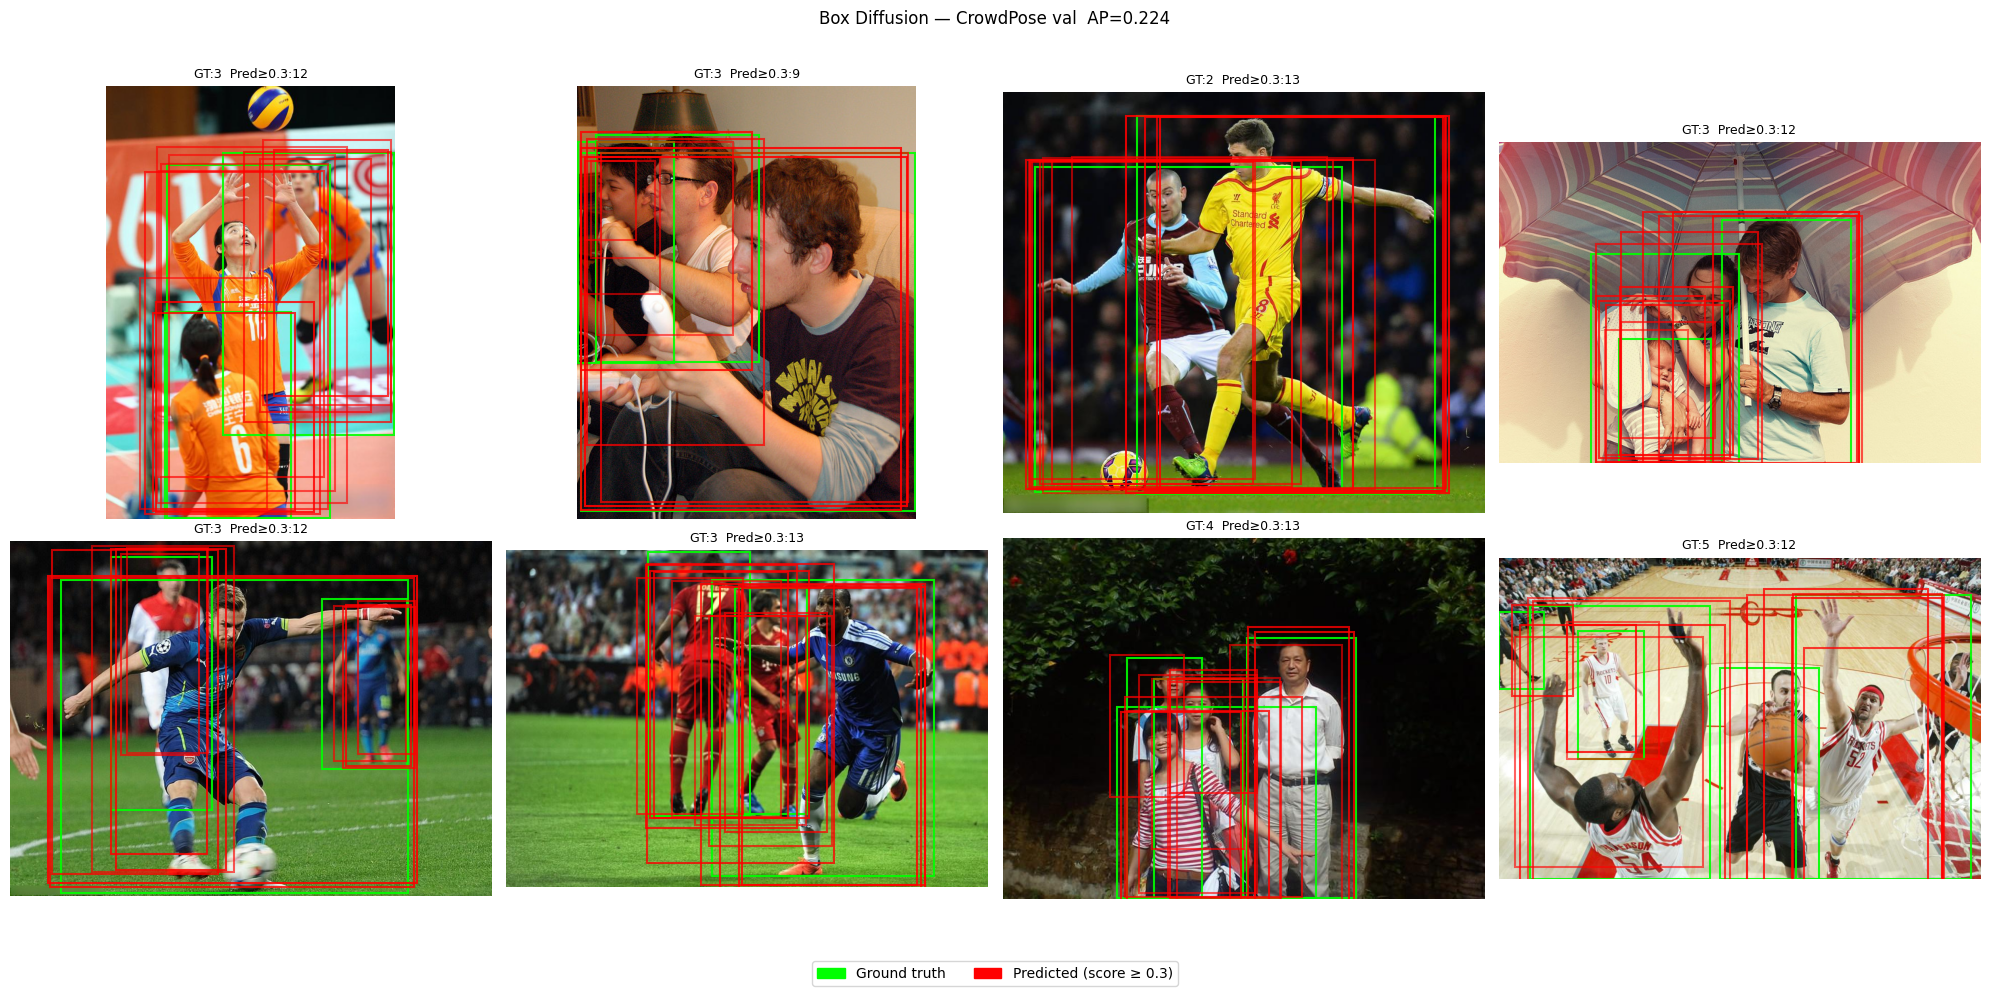

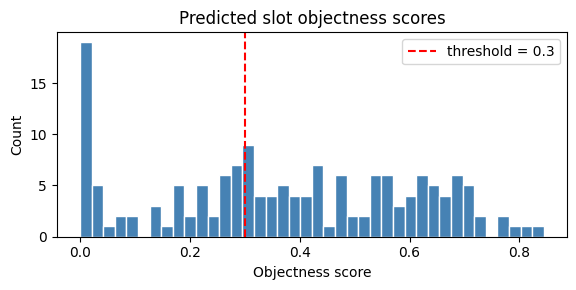

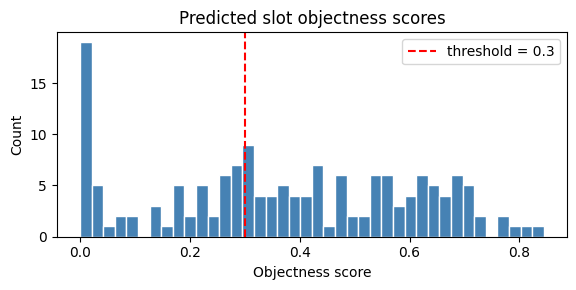

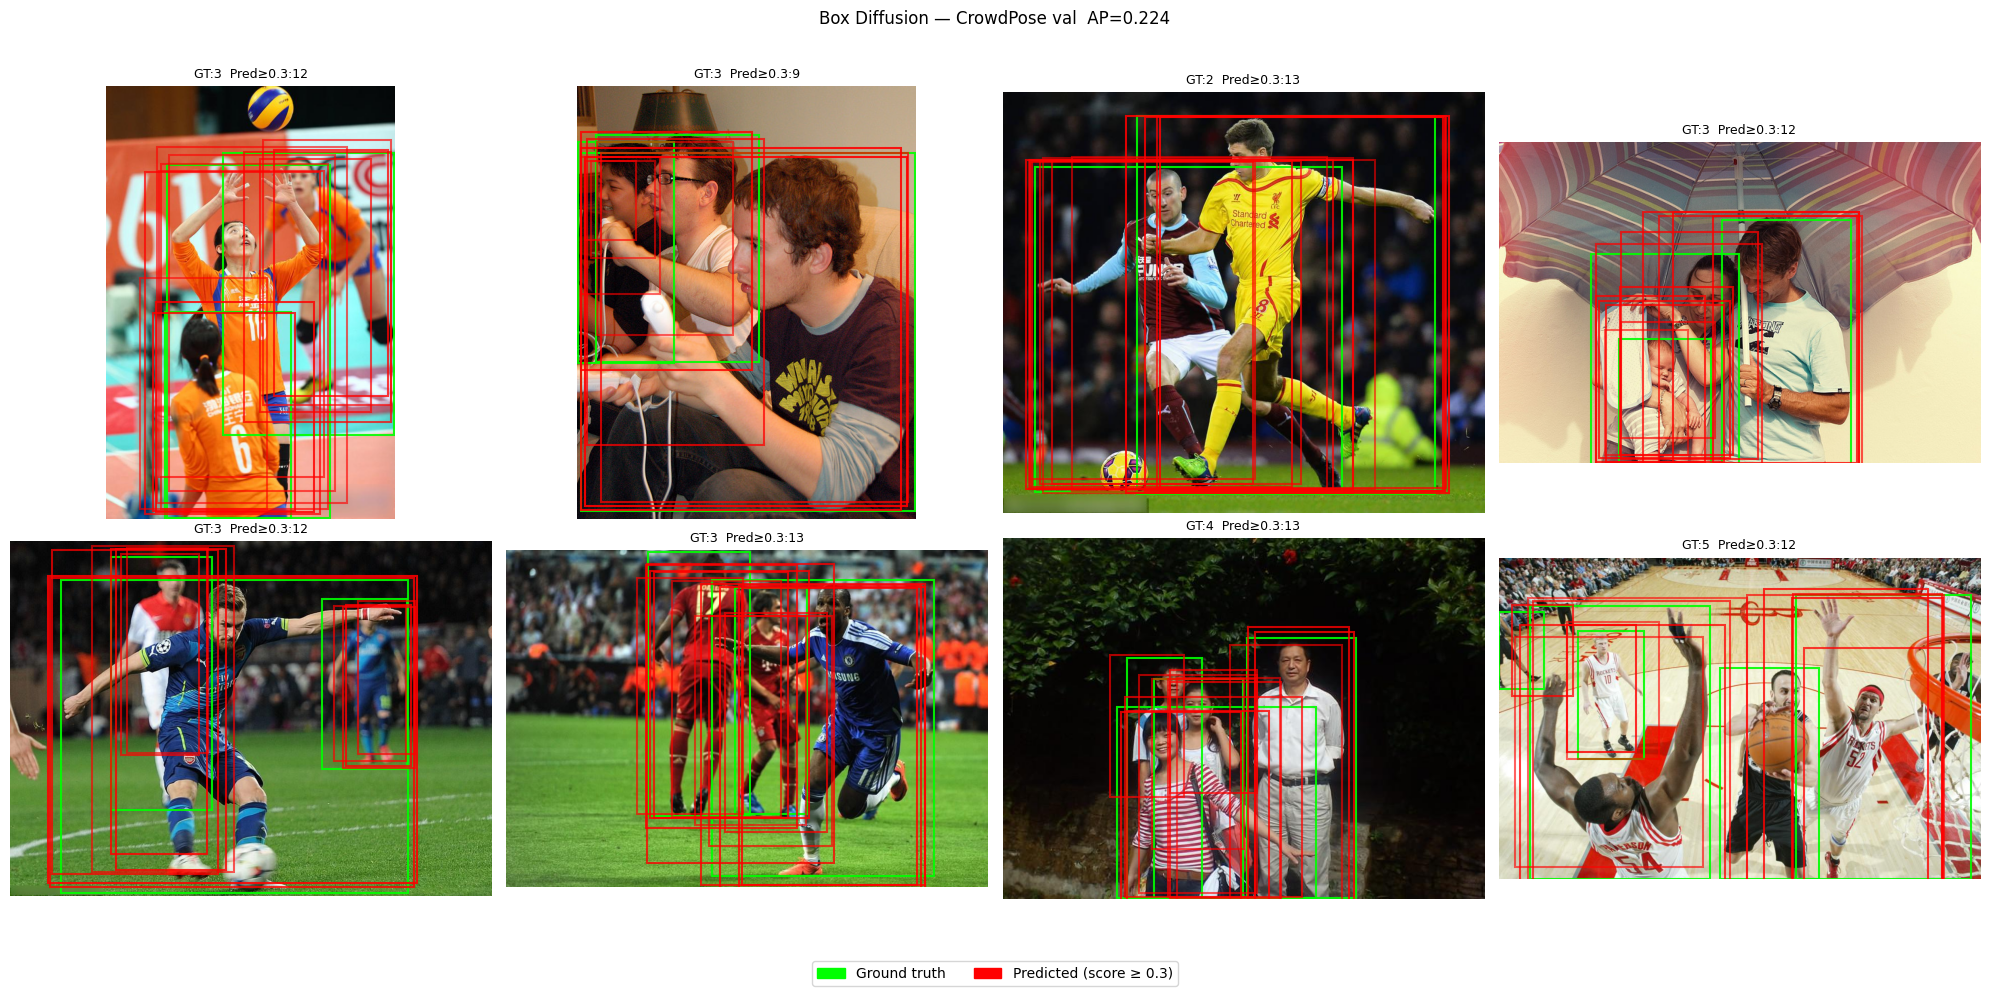

In [13]:
def _draw_boxes(ax, boxes_xyxy, color, alpha=0.9, linewidth=1.5):
    """Draw xyxy boxes on ax."""
    for box in boxes_xyxy:
        x1, y1, x2, y2 = box
        rect = plt.Rectangle(
            (float(x1), float(y1)),
            float(x2 - x1), float(y2 - y1),
            edgecolor=color, facecolor="none",
            linewidth=linewidth, alpha=alpha,
        )
        ax.add_patch(rect)


ncols = min(4, N_IMAGES)
nrows = (N_IMAGES + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows))
axes = np.array(axes).reshape(-1)

for i, (ax, res) in enumerate(zip(axes, results)):
    img_np = res["img_uint8"].permute(1, 2, 0).numpy()
    ax.imshow(img_np)

    # GT boxes (green)
    gt = res["gt_boxes_xywh"]
    if gt is not None and len(gt) > 0:
        gt_np = gt.numpy()
        gx, gy, gw, gh = gt_np[:, 0], gt_np[:, 1], gt_np[:, 2], gt_np[:, 3]
        gt_xyxy = np.stack([gx, gy, gx + gw, gy + gh], axis=-1)
        _draw_boxes(ax, gt_xyxy, color="lime", linewidth=1.5)

    # Predicted boxes (red, filtered by score)
    scores = res["obj_scores"].numpy()
    pred   = res["pred_boxes_xyxy"].numpy()
    keep   = np.where(scores >= SCORE_THRESH)[0]
    keep   = keep[np.argsort(-scores[keep])][:TOP_K]
    for idx in keep:
        s = float(scores[idx])
        rect = plt.Rectangle(
            (float(pred[idx, 0]), float(pred[idx, 1])),
            float(pred[idx, 2] - pred[idx, 0]),
            float(pred[idx, 3] - pred[idx, 1]),
            edgecolor="red", facecolor="none",
            linewidth=1.5, alpha=float(0.4 + 0.6 * s),
        )
        ax.add_patch(rect)

    n_pred = len(keep)
    n_gt   = len(gt) if gt is not None else 0
    ax.set_title(f"GT:{n_gt}  Pred≥{SCORE_THRESH:.1f}:{n_pred}", fontsize=9)
    ax.axis("off")

# Hide unused axes
for ax in axes[len(results):]:
    ax.axis("off")

gt_patch   = mpatches.Patch(color="lime", label="Ground truth")
pred_patch = mpatches.Patch(color="red",  label=f"Predicted (score ≥ {SCORE_THRESH})")
fig.legend(handles=[gt_patch, pred_patch], loc="lower center", ncol=2, fontsize=10)

ap_str = f"  AP={test_ap:.3f}" if test_ap is not None else ""
fig.suptitle(f"Box Diffusion — CrowdPose {SPLIT}{ap_str}", fontsize=12)
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.show()

## 5. Score distribution

In [8]:
all_scores = torch.cat([r["obj_scores"] for r in results]).numpy()

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(all_scores, bins=40, color="steelblue", edgecolor="white")
ax.axvline(SCORE_THRESH, color="red", linestyle="--", label=f"threshold = {SCORE_THRESH}")
ax.set_xlabel("Objectness score")
ax.set_ylabel("Count")
ax.set_title("Predicted slot objectness scores")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Slots above threshold: {(all_scores >= SCORE_THRESH).sum()} / {len(all_scores)} "
      f"({100*(all_scores >= SCORE_THRESH).mean():.1f}%)")

Slots above threshold: 96 / 160 (60.0%)


/tmp/ipykernel_1563614/480365750.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
